In [1]:
import pandas as pd
import numpy as np
from pmdarima import auto_arima

In [2]:
Kandi=pd.read_csv("data\Kandi_final.csv")
Parakou=pd.read_csv("data\Parakou_final.csv")

<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_9732\3890621831.py:1: SyntaxWarning: invalid escape sequence '\K'
  Kandi=pd.read_csv("data\Kandi_final.csv")
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_9732\3890621831.py:2: SyntaxWarning: invalid escape sequence '\P'
  Parakou=pd.read_csv("data\Parakou_final.csv")


In [3]:
Kandi["Pluviometrie"]

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
4012    0.0
4013    0.0
4014    0.0
4015    0.0
4016    0.0
Name: Pluviometrie, Length: 4017, dtype: float64

In [4]:
def changement(x):
    if x<10:
        return f"0{x}"
    else :
        return f"{x}"
Kandi["Date"]=Kandi["annee"].apply(changement)+"-"+Kandi["mois"].apply(changement)+"-"+Kandi["jour"].apply(changement)
Kandi["Date"]=pd.to_datetime(Kandi["Date"])
Kandi=Kandi.set_index("Date")


Parakou["Date"]=Parakou["annee"].apply(changement)+"-"+Parakou["mois"].apply(changement)+"-"+Parakou["jour"].apply(changement)
Parakou["Date"]=pd.to_datetime(Parakou.Date)
Parakou=Parakou.set_index("Date")

In [5]:
Kandi.head()

,Lieu,annee,mois,jour,Pression,Temperature_Max,Temperature_Min,Humidite,Vitesse_Vent,Pluviometrie
Date,,,,,,,,,,
2015-01-01,KANDI_AEROPORT,2015,1,1,979.9,32.0,13.4,32.0,2.4,0.0
2015-01-02,KANDI_AEROPORT,2015,1,2,981.4,30.3,17.4,26.0,2.3,0.0
2015-01-03,KANDI_AEROPORT,2015,1,3,982.8,29.2,17.7,20.0,3.5,0.0
2015-01-04,KANDI_AEROPORT,2015,1,4,983.8,29.0,15.8,20.0,2.8,0.0
2015-01-05,KANDI_AEROPORT,2015,1,5,982.7,29.5,13.5,29.0,3.0,0.0


In [6]:
Kandi["Humidite_lag1"] = Kandi["Humidite"].shift(1)
Kandi["Pression_lag1"] = Kandi["Pression"].shift(1)
Kandi["Vent_lag1"] = Kandi["Vitesse_Vent"].shift(1)
Kandi["Temperature_Max_lag1"] = Kandi["Temperature_Max"].shift(1)
Kandi["Temperature_Min_lag1"] = Kandi["Temperature_Min"].shift(1)
Kandi=Kandi.drop(["Lieu","mois","jour","Temperature_Max","Temperature_Min","Humidite","Vitesse_Vent","Pression"],axis=1)
Kandi=Kandi.dropna(axis=0)

Parakou["Humidite_lag1"] = Parakou["Humidite"].shift(1)
Parakou["Pression_lag1"] = Parakou["Pression"].shift(1)
Parakou["Vent_lag1"] = Parakou["Vitesse_Vent"].shift(1)
Parakou["Temperature_Max_lag1"] = Parakou["Temperature_Max"].shift(1)
Parakou["Temperature_Min_lag1"] = Parakou["Temperature_Min"].shift(1)
Parakou=Parakou.drop(["Lieu","mois","jour","Temperature_Max","Temperature_Min","Humidite","Vitesse_Vent","Pression"],axis=1)
Parakou=Parakou.dropna(axis=0)
Kandi

,annee,Pluviometrie,Humidite_lag1,Pression_lag1,Vent_lag1,Temperature_Max_lag1,Temperature_Min_lag1
Date,,,,,,,
2015-01-02,2015,0.0,32.0,979.9,2.4,32.0,13.4
2015-01-03,2015,0.0,26.0,981.4,2.3,30.3,17.4
2015-01-04,2015,0.0,20.0,982.8,3.5,29.2,17.7
2015-01-05,2015,0.0,20.0,983.8,2.8,29.0,15.8
2015-01-06,2015,0.0,29.0,982.7,3.0,29.5,13.5
...,...,...,...,...,...,...,...
2025-12-27,2025,0.0,33.0,977.2,1.5,37.1,20.7
2025-12-28,2025,0.0,28.0,976.9,1.4,37.4,20.4
2025-12-29,2025,0.0,27.0,977.5,2.0,36.9,19.7


In [7]:
Kandi_y_train=Kandi[Kandi.annee<2024]["Pluviometrie"]
Kandi_y_test=Kandi[2024<=Kandi.annee]["Pluviometrie"]

Kandi_X_train=Kandi[Kandi.annee<2024][["Humidite_lag1","Pression_lag1","Vent_lag1","Temperature_Max_lag1","Temperature_Min_lag1"]]
Kandi_X_test=Kandi[2024<=Kandi.annee][["Humidite_lag1","Pression_lag1","Vent_lag1","Temperature_Max_lag1","Temperature_Min_lag1"]]

Parakou_y_train=Parakou[Parakou.annee<2024]["Pluviometrie"]
Parakou_y_test=Parakou[2024<=Parakou.annee]["Pluviometrie"]

Parakou_X_train=Parakou[Parakou.annee<2024][["Humidite_lag1","Pression_lag1","Vent_lag1","Temperature_Max_lag1","Temperature_Min_lag1"]]
Parakou_X_test=Parakou[2024<=Parakou.annee][["Humidite_lag1","Pression_lag1","Vent_lag1","Temperature_Max_lag1","Temperature_Min_lag1"]]

Kandi_X_train

,Humidite_lag1,Pression_lag1,Vent_lag1,Temperature_Max_lag1,Temperature_Min_lag1
Date,,,,,
2015-01-02,32.0,979.9,2.4,32.0,13.4
2015-01-03,26.0,981.4,2.3,30.3,17.4
2015-01-04,20.0,982.8,3.5,29.2,17.7
2015-01-05,20.0,983.8,2.8,29.0,15.8
2015-01-06,29.0,982.7,3.0,29.5,13.5
...,...,...,...,...,...
2023-12-27,35.0,979.3,2.1,31.5,13.7
2023-12-28,26.0,979.4,2.6,32.7,14.1
2023-12-29,31.0,980.2,2.3,34.0,16.9


In [8]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
def calcul_erreur_auto(X_train,X_test,y_train,y_test,p,q,m):
    if m==7:
        model=auto_arima(y_train,exogenous=X_train,seasonal=True,trace=True,start_p=0,start_q=0,max_p=p+1,max_q=q+1,d=0,start_P=0,start_Q=0,max_P=6,max_Q=6,m=m)
        prediction=model.predict(n_periods=len(y_test),exogenous=X_test)
    else:
        model=auto_arima(y_train,exogenous=X_train,seasonal=True,trace=True,start_p=0,start_q=0,max_p=p+1,max_q=q+1,d=0,start_P=0,start_Q=0,max_P=3,max_Q=3,m=m)
        prediction=model.predict(n_periods=len(y_test),exogenous=X_test)
        
    return {"Resultats":model,"MAE":mean_absolute_error(y_test,prediction),"RMSE":np.sqrt(mean_squared_error(y_test,prediction))}


In [9]:
import matplotlib.pyplot as plt
def calcul_erreur_final(X_train,X_test,y_train,y_test,p,q,P,Q):
    model=auto_arima(y_train,exogenous=X_train,seasonal=True,trace=True,start_p=p,start_q=q,max_p=p,max_q=q,start_P=P,max_P=P,start_Q=Q,max_Q=Q,d=0,m=7)
    prediction=model.predict(n_periods=len(y_test),exogenous=X_test)
    plt.figure(figsize=(10,5))
    plt.plot(y_test.index,y_test,label="Test")
    plt.plot(y_test.index,prediction,label="Prediction")
    plt.legend()
    return {"Resultats":model,"MAE":mean_absolute_error(y_test,prediction),"RMSE":np.sqrt(mean_squared_error(y_test,prediction))}

In [10]:
#Calcul_KandiH=calcul_erreur_auto(Kandi_X_train,Kandi_X_test,Kandi_y_train,Kandi_y_test,6,2,7)

In [11]:
#Calcul_ParakouH=calcul_erreur_auto(Parakou_X_train,Parakou_X_test,Parakou_y_train,Parakou_y_test,3,1,7)

In [12]:
#Calcul_KandiA=calcul_erreur_auto(Kandi_X_train,Kandi_X_test,Kandi_y_train,Kandi_y_test,6,2,30)

In [13]:
#Calcul_ParakouA=calcul_erreur_auto(Parakou_X_train,Parakou_X_test,Parakou_y_train,Parakou_y_test,3,1,30)

In [14]:
#Calcul_KandiH

In [15]:
#Calcul_KandiH["Resultats"].order

In [16]:
"""resultatsH=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_KandiH["Resultats"].order[0],"q":Calcul_KandiH["Resultats"].order[-1],"P":Calcul_KandiH["Resultats"].seasonal_order[0],
                                    "Q":Calcul_KandiH["Resultats"].seasonal_order[2],"MAE":Calcul_KandiH["MAE"],"RMSE":Calcul_KandiH["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_ParakouH["Resultats"].order[0],"q":Calcul_ParakouH["Resultats"].order[-1],"P":Calcul_ParakouH["Resultats"].seasonal_order[0],
                                  "Q":Calcul_ParakouH["Resultats"].seasonal_order[2],"MAE":Calcul_ParakouH["MAE"],"RMSE":Calcul_ParakouH["RMSE"]})],axis=0)

resultatsH"""

'resultatsH=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_KandiH["Resultats"].order[0],"q":Calcul_KandiH["Resultats"].order[-1],"P":Calcul_KandiH["Resultats"].seasonal_order[0],\n                                    "Q":Calcul_KandiH["Resultats"].seasonal_order[2],"MAE":Calcul_KandiH["MAE"],"RMSE":Calcul_KandiH["RMSE"]}),\n                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_ParakouH["Resultats"].order[0],"q":Calcul_ParakouH["Resultats"].order[-1],"P":Calcul_ParakouH["Resultats"].seasonal_order[0],\n                                  "Q":Calcul_ParakouH["Resultats"].seasonal_order[2],"MAE":Calcul_ParakouH["MAE"],"RMSE":Calcul_ParakouH["RMSE"]})],axis=0)\n\nresultatsH'

In [17]:
"""resultatsA=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_KandiA["Resultats"].order[0],"q":Calcul_KandiA["Resultats"].order[-1],"P":Calcul_KandiA["Resultats"].seasonal_order[0],
                                    "Q":Calcul_KandiA["Resultats"].seasonal_order[2],"MAE":Calcul_KandiA["MAE"],"RMSE":Calcul_KandiA["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_ParakouA["Resultats"].order[0],"q":Calcul_ParakouA["Resultats"].order[-1],"P":Calcul_ParakouA["Resultats"].seasonal_order[0],
                                  "Q":Calcul_ParakouA["Resultats"].seasonal_order[2],"MAE":Calcul_ParakouA["MAE"],"RMSE":Calcul_ParakouA["RMSE"]})],axis=0)

resultatsA"""

'resultatsA=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_KandiA["Resultats"].order[0],"q":Calcul_KandiA["Resultats"].order[-1],"P":Calcul_KandiA["Resultats"].seasonal_order[0],\n                                    "Q":Calcul_KandiA["Resultats"].seasonal_order[2],"MAE":Calcul_KandiA["MAE"],"RMSE":Calcul_KandiA["RMSE"]}),\n                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_ParakouA["Resultats"].order[0],"q":Calcul_ParakouA["Resultats"].order[-1],"P":Calcul_ParakouA["Resultats"].seasonal_order[0],\n                                  "Q":Calcul_ParakouA["Resultats"].seasonal_order[2],"MAE":Calcul_ParakouA["MAE"],"RMSE":Calcul_ParakouA["RMSE"]})],axis=0)\n\nresultatsA'

In [18]:
#resultatsH.to_csv("data/resultats_sarima_semestrielle_Avec_VE.csv",index=False)
#resultatsA.to_csv("data/resultats_sarima_Annuel_Avec_VE.csv",index=False)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(5,0,2)[7] intercept   : AIC=24013.269, Time=96.70 sec
 ARIMA(0,0,0)(0,0,0)[7] intercept   : AIC=24204.341, Time=0.12 sec
 ARIMA(0,0,0)(1,0,0)[7] intercept   : AIC=24134.560, Time=1.14 sec
 ARIMA(0,0,0)(0,0,1)[7] intercept   : AIC=24148.147, Time=0.84 sec
 ARIMA(0,0,0)(0,0,0)[7]             : AIC=24527.574, Time=0.05 sec
 ARIMA(0,0,0)(4,0,2)[7] intercept   : AIC=24025.599, Time=37.83 sec
 ARIMA(0,0,0)(5,0,1)[7] intercept   : AIC=24014.417, Time=54.06 sec
 ARIMA(0,0,0)(4,0,1)[7] intercept   : AIC=24029.087, Time=32.78 sec
 ARIMA(0,0,0)(5,0,2)[7]             : AIC=24086.553, Time=14.31 sec

Best model:  ARIMA(0,0,0)(5,0,2)[7] intercept
Total fit time: 237.862 seconds


d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


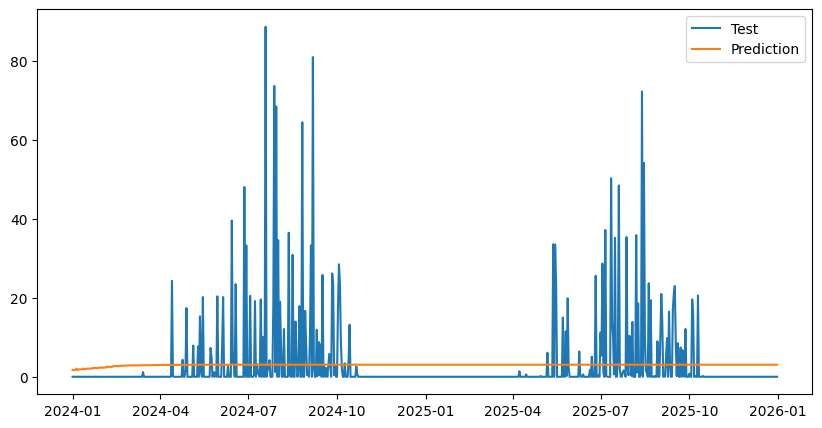

In [19]:
Calcul_KandiF=calcul_erreur_final(Kandi_X_train,Kandi_X_test,Kandi_y_train,Kandi_y_test,0,0,5,2)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(1,0,1)[7] intercept   : AIC=24304.886, Time=1.89 sec
 ARIMA(0,0,0)(0,0,0)[7] intercept   : AIC=24433.359, Time=0.08 sec
 ARIMA(0,0,0)(1,0,0)[7] intercept   : AIC=24364.531, Time=0.71 sec
 ARIMA(0,0,0)(0,0,1)[7] intercept   : AIC=24375.805, Time=0.66 sec
 ARIMA(0,0,0)(0,0,0)[7]             : AIC=24770.228, Time=0.05 sec
 ARIMA(0,0,0)(1,0,1)[7]             : AIC=24388.013, Time=0.45 sec

Best model:  ARIMA(0,0,0)(1,0,1)[7] intercept
Total fit time: 3.906 seconds


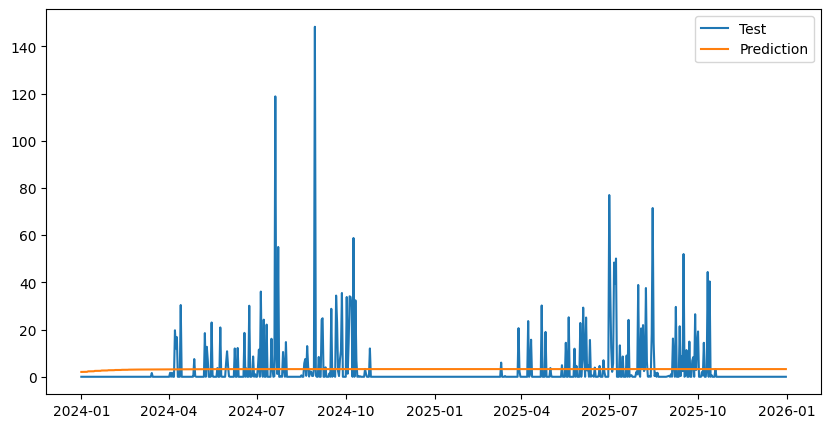

In [20]:
Calcul_ParakouF=calcul_erreur_final(Parakou_X_train,Parakou_X_test,Parakou_y_train,Parakou_y_test,0,0,1,1)